#### DATASET INVESTIGATION

Preprocessing investigation

In [1]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("train_labels.csv")

print(df["class"].nunique())
print(df["class"].unique())

print(df["image_id"].nunique())

print(df["class"].value_counts())


8
<StringArray>
[  'DogEye', 'DogMouth',  'DogFace',  'DogNose',  'CatNose',  'CatFace',
 'CatMouth',   'CatEye']
Length: 8, dtype: str
63660
class
CatEye      13884
DogEye      11580
CatNose      6942
CatFace      6942
CatMouth     6942
DogMouth     5790
DogFace      5790
DogNose      5790
Name: count, dtype: int64


In [2]:
import os
from PIL import Image 

folder_path = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\train\train"

file_extension = ".jpg"

data_list = []

for filename in os.listdir(folder_path):
    if filename.lower().endswith(file_extension):
        file_path = os.path.join(folder_path, filename)
        try:
            file_size_bytes = os.path.getsize(file_path)
            file_size_mb = file_size_bytes / (1024)
            
           
            with Image.open(file_path) as img:
                width, height = img.size
            
       
            print(f"{filename:<30} | {file_size_mb:<15.2f} | {width}x{height}")
            data_list.append({
                'File Name': filename,
                'File Size (MB)': file_size_mb,
                'Width': width,
                'Height': height
            })
        except Exception as e:
            print(f"Could not process {filename}: {e}")


df = pd.DataFrame(data_list)

csv_output_path = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\image_size_data.csv"

df.to_csv(csv_output_path, index=False)
print(f"\nSuccessfully logged all data to {csv_output_path}")


00001.jpg                      | 1.45            | 36x36
00002.jpg                      | 23.40           | 214x157
00003.jpg                      | 6.55            | 97x97
00004.jpg                      | 5.47            | 110x110
00005.jpg                      | 1.69            | 42x42
00006.jpg                      | 1.35            | 28x28
00007.jpg                      | 14.88           | 182x135
00008.jpg                      | 6.09            | 128x128
00009.jpg                      | 90.48           | 343x376
00010.jpg                      | 1.25            | 36x36
00011.jpg                      | 10.92           | 149x148
00012.jpg                      | 4.82            | 94x70
00013.jpg                      | 3.57            | 98x68
00014.jpg                      | 21.20           | 188x182
00015.jpg                      | 13.14           | 158x158
00016.jpg                      | 11.54           | 140x140
00017.jpg                      | 2.30            | 66x66
00018.jpg    

KeyboardInterrupt: 

=== FILE SIZE ===
Average: 10.61
Largest: 1233.08
Smallest: 0.64

=== IMAGE DIMENSIONS ===
Average width:  113 px
Average height: 110 px
Largest width:  2219 px
Largest height: 2219 px
Average total pixels: 22026
Largest total pixels: 4923961

=== LARGEST FILES ===
       File Size (kB)  Width  Height
8325      1233.079102   2219    2219
47667      976.843750   2190    2070
7890       780.717773   1429    1429
16819      747.480469   1791    1736
44618      742.433594   1719    1720
10529      685.170898   1623    1624
9071       643.545898   1424    1425
55653      631.757812   1383    1384
52413      628.821289   1786    1787
539        554.873047   1281    1280

=== LARGEST DIMENSIONS ===
       Width  Height  total_pixels  File Size (kB)
8325    2219    2219       4923961     1233.079102
47667   2190    2070       4533300      976.843750
2694    1873    1873       3508129      504.759766
52413   1786    1787       3191582      628.821289
16819   1791    1736       3109176      747.

C:\Users\wah31\AppData\Local\Temp\ipykernel_37716\304533468.py:71: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(
C:\Users\wah31\AppData\Local\Temp\ipykernel_37716\304533468.py:89: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(


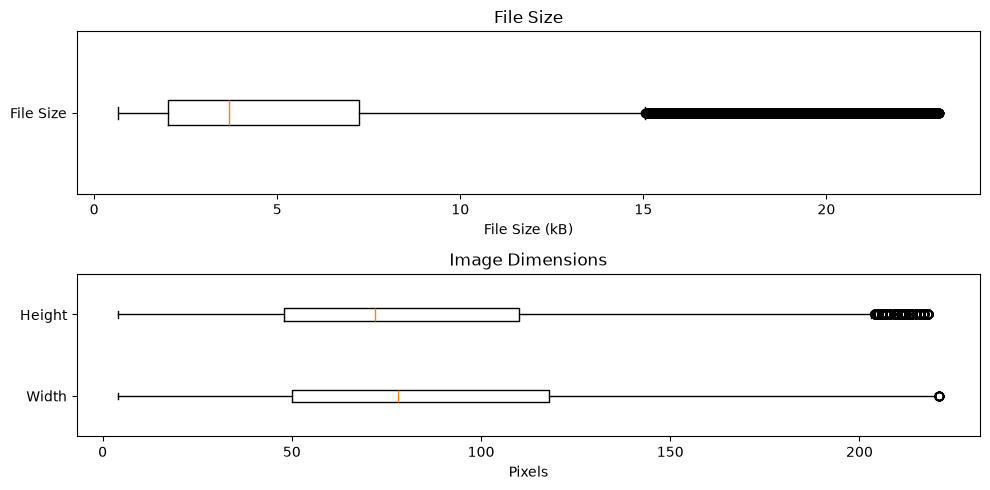

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load CSV
df = pd.read_csv("image_size_data.csv")


# Summary statistics


print("=== FILE SIZE ===")
print(f"Average: {df['File Size (kB)'].mean():.2f}")
print(f"Largest: {df['File Size (kB)'].max():.2f}")
print(f"Smallest: {df['File Size (kB)'].min():.2f}")

print("\n=== IMAGE DIMENSIONS ===")
print(f"Average width:  {df['Width'].mean():.0f} px")
print(f"Average height: {df['Height'].mean():.0f} px")
print(f"Largest width:  {df['Width'].max():.0f} px")
print(f"Largest height: {df['Height'].max():.0f} px")

# Total pixels
df["total_pixels"] = df["Width"] * df["Height"]

print(f"Average total pixels: {df['total_pixels'].mean():.0f}")
print(f"Largest total pixels: {df['total_pixels'].max():.0f}")



# Largest files


print("\n=== LARGEST FILES ===")

largest_files = df.sort_values(
    by="File Size (kB)",
    ascending=False
)

print(largest_files[["File Size (kB)", "Width", "Height"]].head(10))



# Largest dimensions


print("\n=== LARGEST DIMENSIONS ===")

largest_dimensions = df.sort_values(
    by="total_pixels",
    ascending=False
)
print(largest_dimensions[["Width", "Height", "total_pixels", "File Size (kB)"]].head(10))
print("\n=== SMALLEST DIMENSIONS ===")

smallest_dimensions = df.sort_values(
    by="total_pixels",
    ascending= True
)
print(smallest_dimensions[["Width", "Height", "total_pixels", "File Size (kB)"]].head(10))




file_size = df["File Size (kB)"].dropna()
file_size_95 = file_size[file_size <= file_size.quantile(0.90)]

fig, axes = plt.subplots(2, 1, figsize=(10, 5))

# File size
axes[0].boxplot(
    file_size_95,
    vert=False
)

axes[0].set_title("File Size")
axes[0].set_xlabel("File Size (kB)")
axes[0].set_yticks([1])
axes[0].set_yticklabels(["File Size"])

width = df["Width"].dropna()
height = df["Height"].dropna()

width_95 = width[width <= width.quantile(0.90)]
height_95 = height[height <= height.quantile(0.90)]


# Image dimensions: width + height
axes[1].boxplot(
    [
        width_95,
        height_95
    ],
    vert=False
)

axes[1].set_title("Image Dimensions")
axes[1].set_xlabel("Pixels")
axes[1].set_yticks([1, 2])
axes[1].set_yticklabels(["Width", "Height"])


plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

df = pd.read_csv("image_size_data.csv")

small_images = df[(df["Width"] < 10) | (df["Height"] < 10)]

for filename in small_images["File Name"]:
    print(filename)

00119.jpg
01594.jpg
02188.jpg
02480.jpg
05361.jpg
10106.jpg
12429.jpg
13563.jpg
14181.jpg
21923.jpg
29282.jpg
29753.jpg
32523.jpg
36018.jpg
38794.jpg
39855.jpg
43884.jpg
51449.jpg
52816.jpg
59018.jpg
60897.jpg


Model Comparison

In [ ]:
import pandas as pd

cnn_csv = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\test_results\CNN_Base_15_20261006_185917_results_preditctions.csv"

vit_csv = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\test_results\vit_b32_test_predictions.csv"


cnn_df = pd.read_csv(cnn_csv, dtype={"image_id": str})
vit_df = pd.read_csv(vit_csv, dtype={"image_id": str})

# Remove .jpg so both files use the same image_id format
cnn_df["image_id"] = (
    cnn_df["image_id"]
    .astype(str)
    .str.replace(".jpg", "", regex=False)
)

vit_df["image_id"] = (
    vit_df["image_id"]
    .astype(str)
    .str.replace(".jpg", "", regex=False)
)

# Merge CNN and ViT predictions
merged = cnn_df.merge(
    vit_df,
    on="image_id",
    suffixes=("_cnn", "_vit")
)

print("Matched rows:", len(merged))
print(merged.head())

# Compare predictions
results = []

for _, row in merged.iterrows():

    cnn_class = row["prediction"]
    vit_class = row["class"]

    cnn_probability = row[f"{cnn_class}_prob_cnn"]
    vit_probability = row[f"{vit_class}_prob_vit"]

    if cnn_class == vit_class:

        final_class = cnn_class
        decision = "Agree"

    else:

        if cnn_probability >= vit_probability:
            final_class = cnn_class
            decision = "CNN higher probability"
        else:
            final_class = vit_class
            decision = "ViT higher probability"

    results.append({
        "image_id": row["image_id"],
        "cnn_class": cnn_class,
        "cnn_probability": cnn_probability,
        "vit_class": vit_class,
        "vit_probability": vit_probability,
        "final_class": final_class,
        "decision": decision
    })

comparison_df = pd.DataFrame(results)

print("\nComparison:")
print(comparison_df.head())

print("\nPrediction disagreements:",
      (comparison_df["cnn_class"] != comparison_df["vit_class"]).sum())

print("\nModel agreement:",
      (comparison_df["cnn_class"] == comparison_df["vit_class"]).sum())

comparison_df.to_csv(
    "model_comparison.csv",
    index=False
)

print("\nSaved as model_comparison.csv")



Matched rows: 29443
  image_id     class  confidence_cnn  CatEye_prob_cnn  DogEye_prob_cnn  \
0    00001    DogEye        0.999997     2.750691e-06     9.999973e-01   
1    00002  DogMouth        0.988035     3.848460e-07     2.146621e-05   
2    00003   DogNose        0.999792     8.743991e-09     3.109590e-08   
3    00004   DogFace        0.999856     2.176145e-13     6.710131e-15   
4    00005  CatMouth        0.999974     4.563057e-12     2.293739e-21   

   CatFace_prob_cnn  DogFace_prob_cnn  CatMouth_prob_cnn  DogMouth_prob_cnn  \
0      4.531350e-11      1.375783e-10       1.975024e-12       7.297007e-11   
1      1.245838e-08      2.130149e-05       1.001350e-04       9.880354e-01   
2      3.120999e-08      4.303088e-05       7.020063e-08       1.530944e-04   
3      1.444374e-04      9.998555e-01       1.462745e-10       1.006703e-14   
4      8.020505e-16      1.014488e-20       9.999744e-01       9.372329e-19   

   CatNose_prob_cnn  ...  prediction confidence_vit  CatEye_

In [ ]:
disagreements = comparison_df[
    comparison_df["cnn_class"] != comparison_df["vit_class"]
]

print("Total disagreements:", len(disagreements))
print(disagreements.to_string(index=False))

Total disagreements: 5371
image_id cnn_class  cnn_probability vit_class  vit_probability final_class               decision
   00007   CatNose     1.322279e-01  CatMouth     4.732077e-01    CatMouth ViT higher probability
   00010  CatMouth     8.581774e-05   CatNose     1.868133e-01     CatNose ViT higher probability
   00014  DogMouth     3.563439e-10   DogNose     3.675646e-01     DogNose ViT higher probability
   00018   DogNose     1.772662e-07  DogMouth     2.878252e-01    DogMouth ViT higher probability
   00020    CatEye     5.325749e-04    DogEye     1.604583e-01      DogEye ViT higher probability
   00022  DogMouth     3.077936e-07   DogNose     4.877180e-01     DogNose ViT higher probability
   00024   DogNose     1.396312e-06  DogMouth     3.479004e-01    DogMouth ViT higher probability
   00026    DogEye     1.795416e-02  DogMouth     2.764252e-03      DogEye CNN higher probability
   00039  CatMouth     1.304315e-05   CatNose     2.144190e-01     CatNose ViT higher probab

In [ ]:
disagreements = comparison_df[
    comparison_df["cnn_class"] != comparison_df["vit_class"]
]

cnn_more_confident = (
    disagreements["cnn_probability"] > disagreements["vit_probability"]
).sum()

vit_more_confident = (
    disagreements["vit_probability"] > disagreements["cnn_probability"]
).sum()

ties = (
    disagreements["cnn_probability"] == disagreements["vit_probability"]
).sum()

print("Total disagreements:", len(disagreements))
print("CNN more confident:", cnn_more_confident)
print("ViT more confident:", vit_more_confident)

disagreements = comparison_df[
    comparison_df["cnn_class"] != comparison_df["vit_class"]
]

print("\nDisagreement pairs:")
print(
    disagreements.groupby(
        ["cnn_class", "vit_class"]
    ).size().sort_values(ascending=False)
)


Total disagreements: 5371
CNN more confident: 2155
ViT more confident: 3216

Disagreement pairs:
cnn_class  vit_class
CatNose    CatMouth     1095
CatMouth   CatNose       681
DogNose    DogMouth      593
DogEye     CatEye        365
DogMouth   DogNose       341
CatEye     DogEye        163
DogNose    DogEye        160
DogEye     DogNose       155
           DogMouth      135
CatEye     CatFace       111
DogEye     DogFace       103
DogNose    CatEye         86
DogMouth   DogEye         84
CatEye     CatMouth       74
           CatNose        71
CatMouth   CatEye         65
CatNose    CatEye         64
           DogEye         62
DogNose    DogFace        61
DogMouth   DogFace        60
CatEye     DogFace        53
DogEye     CatNose        52
           CatFace        52
CatMouth   DogEye         48
CatEye     DogNose        45
DogEye     CatMouth       44
CatNose    DogMouth       42
           DogNose        41
CatEye     DogMouth       41
DogNose    CatNose        41
CatMouth   C